# 📊 Log_Visualizer — Visualisation des Données

**Université de Lomé — LARSI | Stage IA & Big Data**

Ce notebook reproduit les figures du mémoire *«Approche non supervisée pour la détection
d'intrusion basée sur des fichiers journaux»* à partir du fichier nettoyé.

---

## 📁 Arborescence
```
logs_output/
├── Combined_All_Logs_Cleaned.csv   ← ENTRÉE (Log_Cleaner.ipynb)
└── figures/
    ├── fig3_3_heatmap_annee_mois.png
    ├── fig3_4_repartition_temporelle.png
    ├── fig3_5_distribution_methodes.png
    ├── fig3_6_distribution_statuscode.png
    ├── fig3_7_distribution_referer.png
    ├── fig3_8_distribution_useragent.png
    ├── fig3_9_matrice_correlation.png
    ├── fig3_10_correlation_clustering.png
    └── fig3_11_pca_variance_cumulee.png
```

## 🗂️ Figures produites

| Figure | Section | Description |
|--------|---------|-------------|
| 3.3 | §3.3.4 | Heatmap répartition logs par année et mois |
| 3.4 | §3.3.4 | Répartition temporelle des logs |
| 3.5 | §3.3.10 | Distribution des méthodes HTTP |
| 3.6 | §3.3.10 | Distribution des codes de statut |
| 3.7 | §3.3.10 | Distribution des référents |
| 3.8 | §3.3.10 | Distribution des User-Agents |
| 3.9 | §3.10.1 | Matrice de corrélation |
| 3.10 | §3.11 | Matrice de corrélation + Clustering hiérarchique |
| 3.11 | §3.13.3 | Variance cumulée expliquée par les composantes PCA |

## 1 -Importation des bibliotheques nécessaires 

In [15]:
# ============================================================
# CELLULE 1 — IMPORTS
# ============================================================

import numpy  as np
import pandas as pd
import matplotlib.pyplot   as plt
import matplotlib.ticker   as ticker
import seaborn             as sns
from pathlib               import Path
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# Style global — sobre et lisible comme dans le mémoire
plt.rcParams.update({
    'figure.dpi'      : 150,
    'savefig.dpi'     : 300,
    'font.size'       : 11,
    'axes.titlesize'  : 13,
    'axes.titleweight': 'bold',
    'axes.labelsize'  : 11,
    'figure.facecolor': 'white',
})
sns.set_style('whitegrid')

print('✅ Imports OK')

✅ Imports OK


## 2- Chemins & Chargement des données 

In [16]:
# ============================================================
# CELLULE 2 — CHEMINS & CHARGEMENT
# ============================================================

INPUT_PATH  = r"C:\Users\DELL\Desktop\projet\logs_output\Ancien_site web\Access_log\Access_log_cleaned.csv"
FIGURES_DIR = Path(r"C:\Users\DELL\Desktop\projet\logs_output\Ancien_site web\Access_log\figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name: str):
    """Sauvegarde une figure en PNG 300 DPI dans logs_output/figures/."""
    path = FIGURES_DIR / name
    fig.savefig(path, dpi=300, bbox_inches='tight')
    print(f'  {path.name}')

# Chargement
df = pd.read_csv(INPUT_PATH, low_memory=False)
df['datetime'] = pd.to_datetime(df['datetime'], utc=True, errors='coerce')
df = df[df['datetime'].notna()].copy()

print(f'✅ Données chargées : {len(df):,d} lignes × {len(df.columns)} colonnes')
print(f'   Période : {df["datetime"].min()}  →  {df["datetime"].max()}')
print(f'   Figures  → {FIGURES_DIR}')

✅ Données chargées : 41,433 lignes × 62 colonnes
   Période : 2021-07-18 03:28:12+00:00  →  2021-08-19 08:25:53+00:00
   Figures  → C:\Users\DELL\Desktop\projet\logs_output\Ancien_site web\Access_log\figures


## 3- Heatmap de la repartition des logs par années et mois 

  fig3_3_heatmap_annee_mois.png


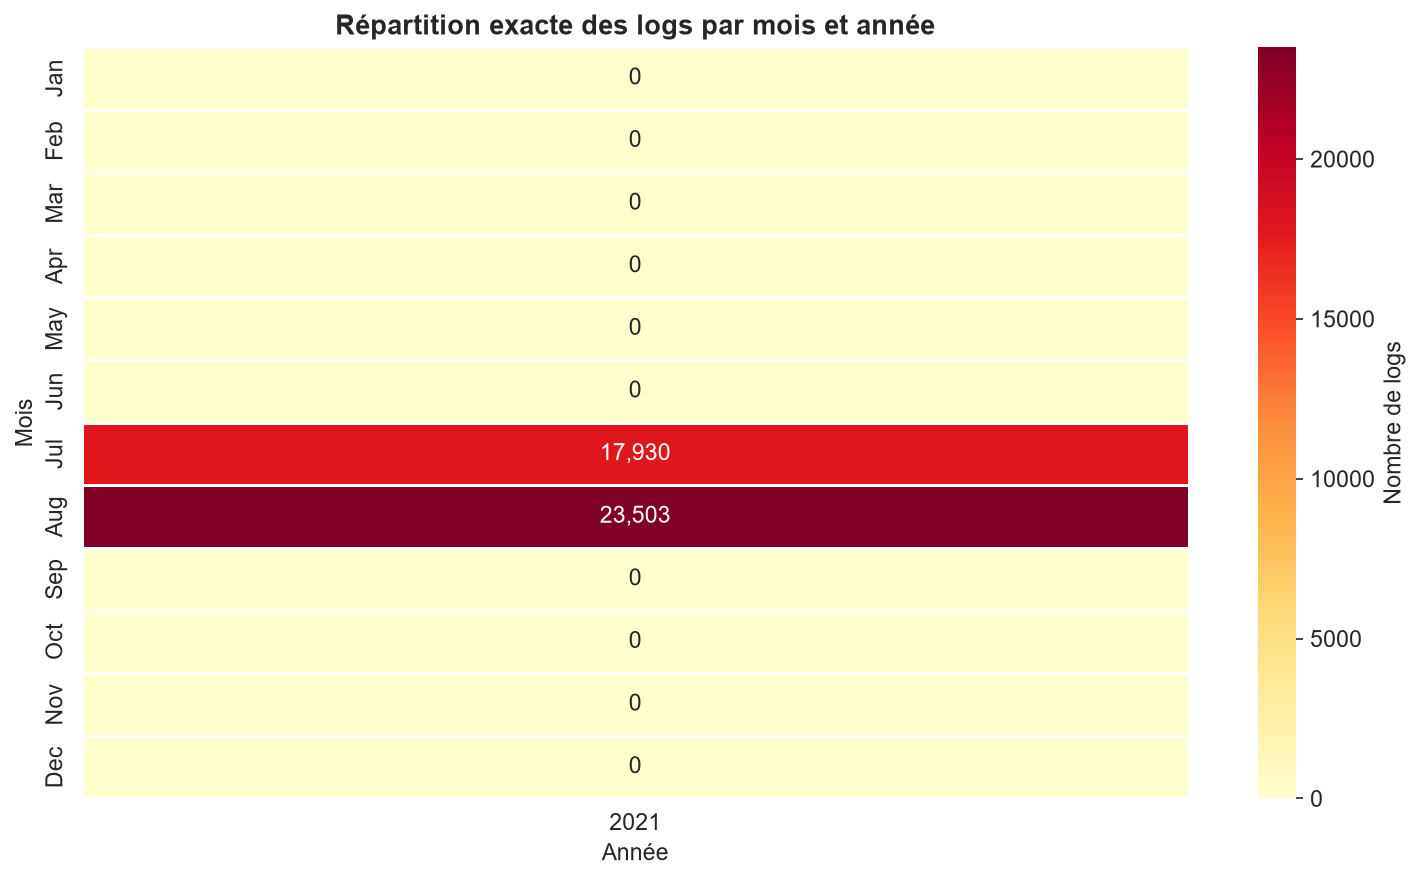

In [17]:
# =========================================================
# Heatmap de la répartition des logs par année et mois
# ============================================================

df['_year']  = df['datetime'].dt.year
df['_month'] = df['datetime'].dt.strftime('%b')  # Jan, Feb, ...

# Ordre des mois
MONTH_ORDER = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']

pivot = (
    df.groupby(['_month', '_year'])
      .size()
      .reset_index(name='Logs')
      .pivot(index='_month', columns='_year', values='Logs')
      .reindex(MONTH_ORDER)
      .fillna(0)
      .astype(int)
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    pivot,
    ax       = ax,
    fmt      = ',d',
    annot    = True,
    cmap     = 'YlOrRd',
    linewidths = 0.5,
    cbar_kws = {'label': 'Nombre de logs'},
)
ax.set_title('Répartition exacte des logs par mois et année')
ax.set_xlabel('Année')
ax.set_ylabel('Mois')
plt.tight_layout()
save(fig, 'fig3_3_heatmap_annee_mois.png')
plt.show()

df.drop(columns=['_year', '_month'], inplace=True)

## Repartition temporelle des logs

  fig3_4_repartition_temporelle.png


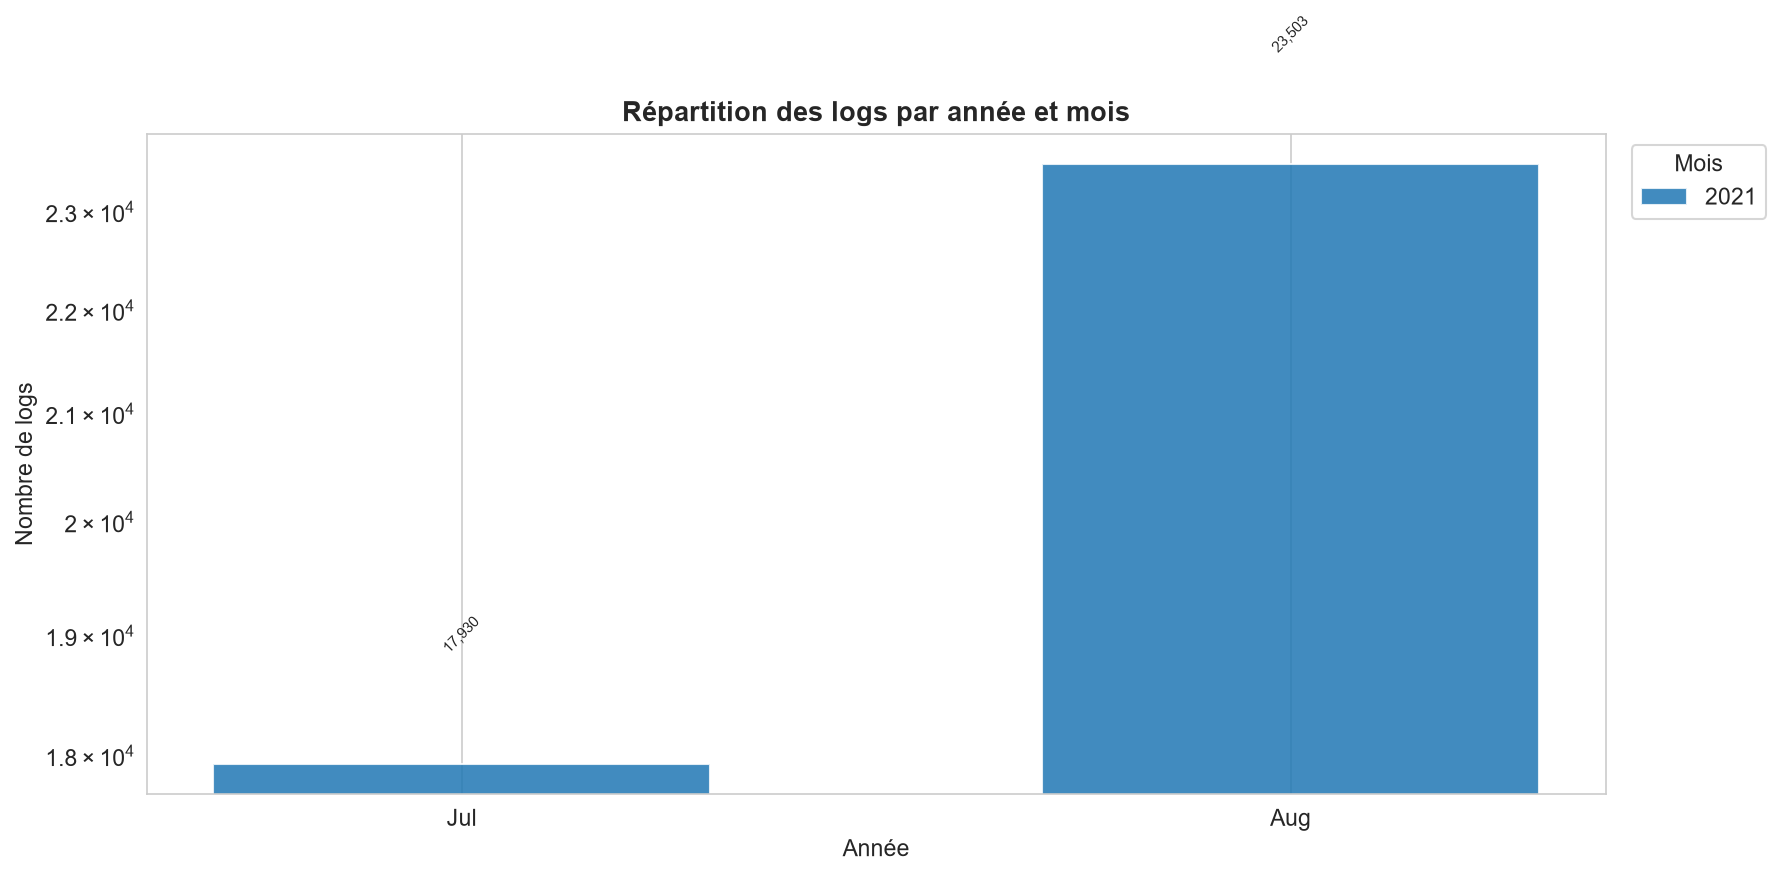

In [18]:
# ============================================================
# CELLULE 4 — FIGURE 3.4
# Répartition temporelle des logs (échelle log)
# ============================================================

df['_year']  = df['datetime'].dt.year
df['_month'] = df['datetime'].dt.strftime('%b')

MONTH_ORDER = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']
COLORS = plt.cm.tab10.colors

grouped = (
    df.groupby(['_year', '_month'])
      .size()
      .reset_index(name='count')
)
grouped['_month_num'] = pd.Categorical(
    grouped['_month'], categories=MONTH_ORDER, ordered=True
)
grouped = grouped.sort_values(['_year', '_month_num'])

fig, ax = plt.subplots(figsize=(12, 6))
years = sorted(grouped['_year'].unique())

for i, year in enumerate(years):
    sub = grouped[grouped['_year'] == year]
    ax.bar(
        sub['_month'].values,
        sub['count'].values,
        label  = str(year),
        color  = COLORS[i % len(COLORS)],
        alpha  = 0.85,
        width  = 0.6,
    )
    # Annotations sur les barres non nulles
    for _, row in sub.iterrows():
        if row['count'] > 0:
            ax.text(
                row['_month'], row['count'] * 1.05,
                f"{int(row['count']):,}",
                ha='center', va='bottom', fontsize=7, rotation=45
            )

ax.set_yscale('log')
ax.set_title('Répartition des logs par année et mois')
ax.set_xlabel('Année')
ax.set_ylabel('Nombre de logs')
ax.legend(title='Mois', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
save(fig, 'fig3_4_repartition_temporelle.png')
plt.show()

df.drop(columns=['_year', '_month'], inplace=True)

## 5-Distribution de la variable Méthodes 

  fig3_5_distribution_methodes.png


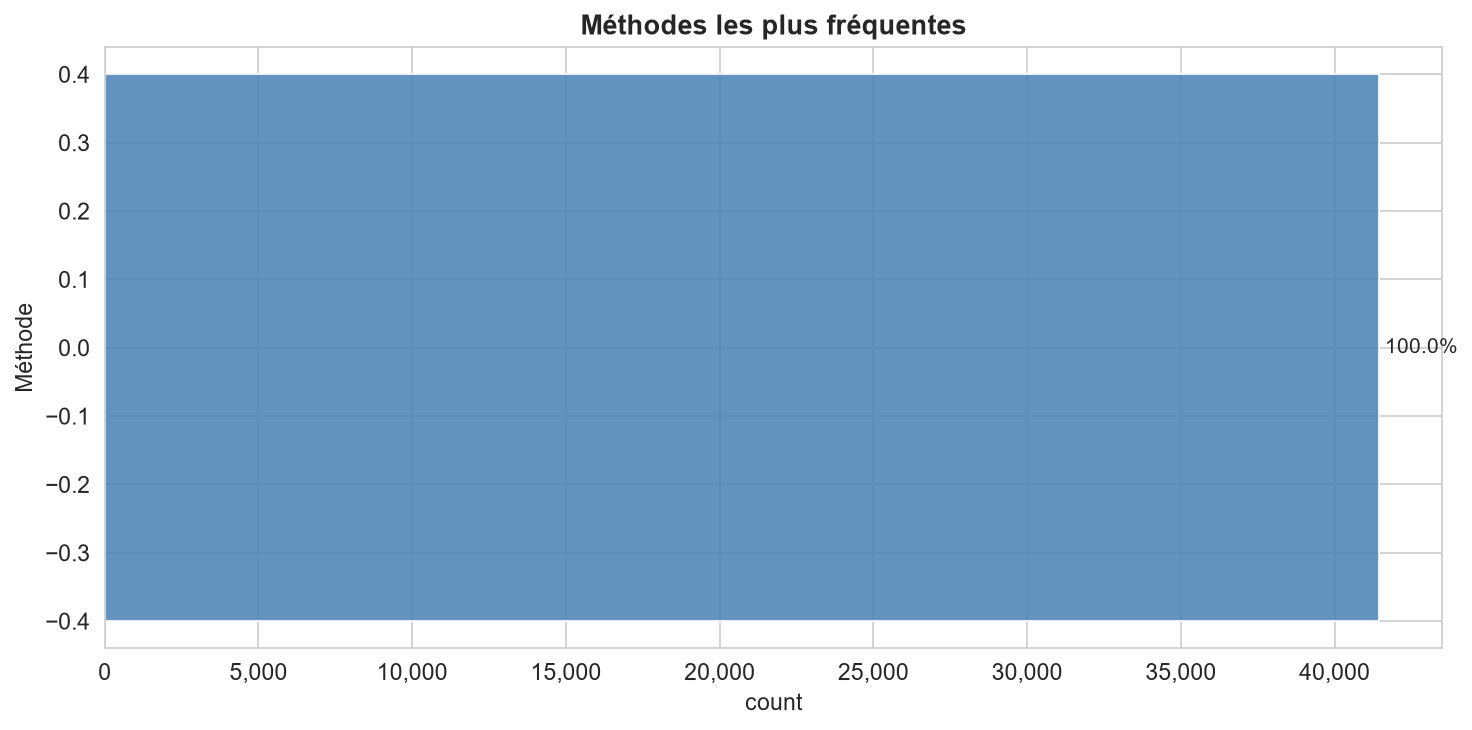

In [19]:
# ============================================================
# CELLULE 5 — FIGURE 3.5
# Distribution de la variable Méthodes
# ============================================================

if 'method' in df.columns:
    counts = (
        df['method']
        .value_counts()
        .head(10)
        .sort_values()          # croissant pour barh
    )
    total = len(df)

    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.barh(
        counts.index, counts.values,
        color='steelblue', alpha=0.85, edgecolor='white'
    )

    # Annotations pourcentage
    for bar, val in zip(bars, counts.values):
        pct = val / total * 100
        ax.text(
            bar.get_width() + total * 0.005,
            bar.get_y() + bar.get_height() / 2,
            f'{pct:.1f}%',
            va='center', fontsize=10
        )

    ax.set_title('Méthodes les plus fréquentes')
    ax.set_xlabel('count')
    ax.set_ylabel('Méthode')
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
    plt.tight_layout()
    save(fig, 'fig3_5_distribution_methodes.png')
    plt.show()
else:
    print('⚠ Colonne "method" absente.')

## 6- Distribution des codes de statut HTTP

  fig3_6_distribution_statuscode.png


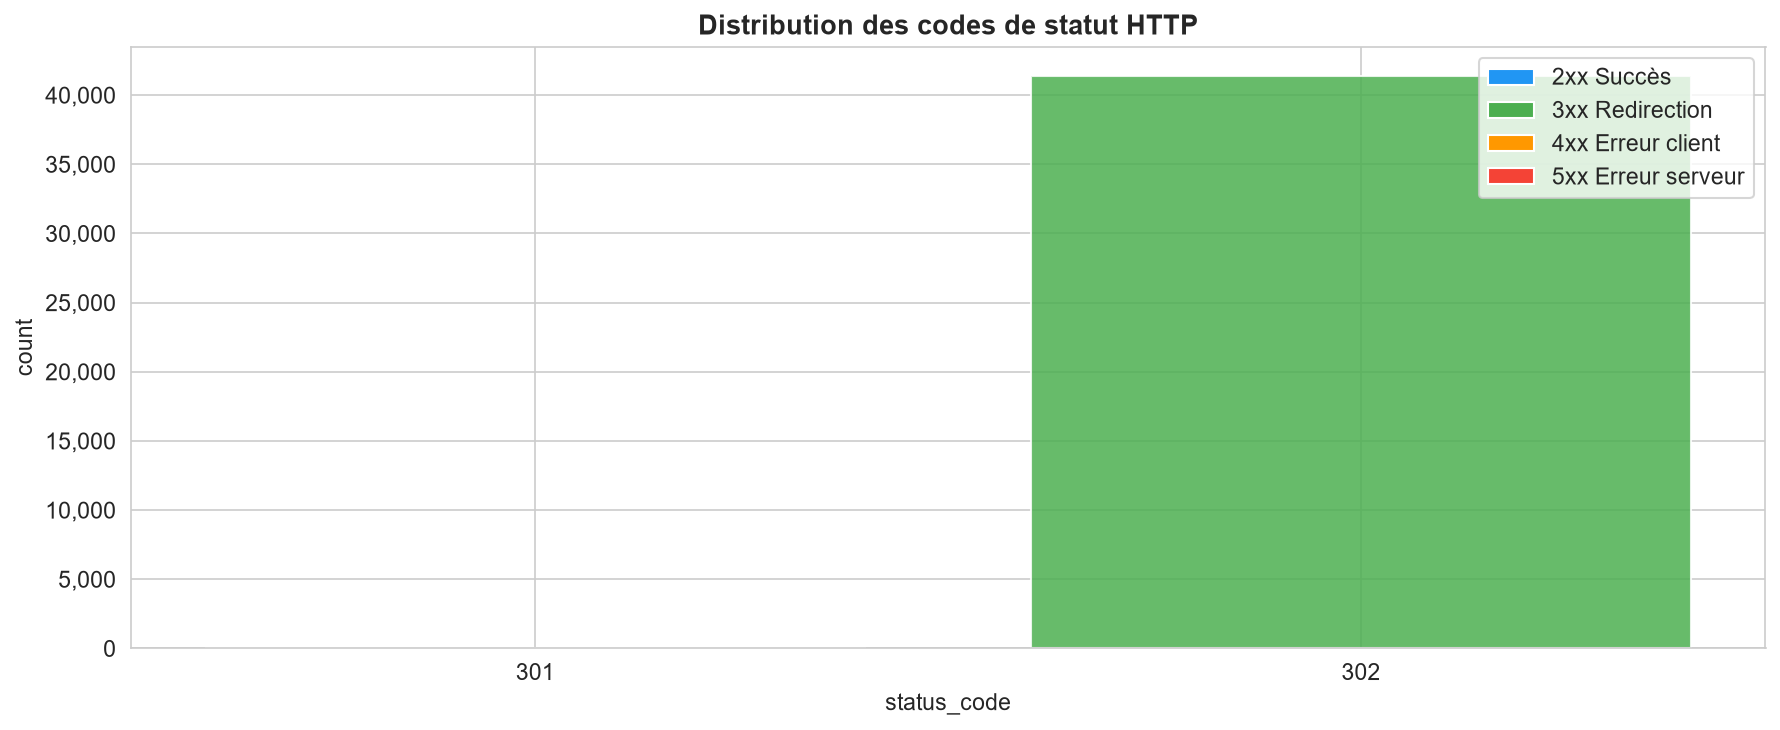

In [20]:
# ============================================================
# CELLULE 6 — FIGURE 3.6
# Distribution des codes de statut HTTP
# ============================================================

if 'status_code' in df.columns:
    status_num = pd.to_numeric(df['status_code'], errors='coerce').dropna()
    counts = status_num.value_counts().sort_index()

    fig, ax = plt.subplots(figsize=(12, 5))

    # Couleur selon la catégorie
    def _status_color(code):
        c = int(code)
        if 200 <= c < 300: return '#2196F3'   # bleu  — succès
        if 300 <= c < 400: return '#4CAF50'   # vert  — redirection
        if 400 <= c < 500: return '#FF9800'   # orange — erreur client
        if 500 <= c < 600: return '#F44336'   # rouge  — erreur serveur
        return '#9E9E9E'

    colors = [_status_color(c) for c in counts.index]
    ax.bar(counts.index.astype(str), counts.values,
           color=colors, alpha=0.85, edgecolor='white')

    ax.set_title('Distribution des codes de statut HTTP')
    ax.set_xlabel('status_code')
    ax.set_ylabel('count')
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

    # Légende catégories
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#2196F3', label='2xx Succès'),
        Patch(facecolor='#4CAF50', label='3xx Redirection'),
        Patch(facecolor='#FF9800', label='4xx Erreur client'),
        Patch(facecolor='#F44336', label='5xx Erreur serveur'),
    ]
    ax.legend(handles=legend_elements, loc='upper right')
    plt.tight_layout()
    save(fig, 'fig3_6_distribution_statuscode.png')
    plt.show()
else:
    print('⚠ Colonne "status_code" absente.')

## 7 Distribution de la variable referent

  fig3_7_distribution_referer.png


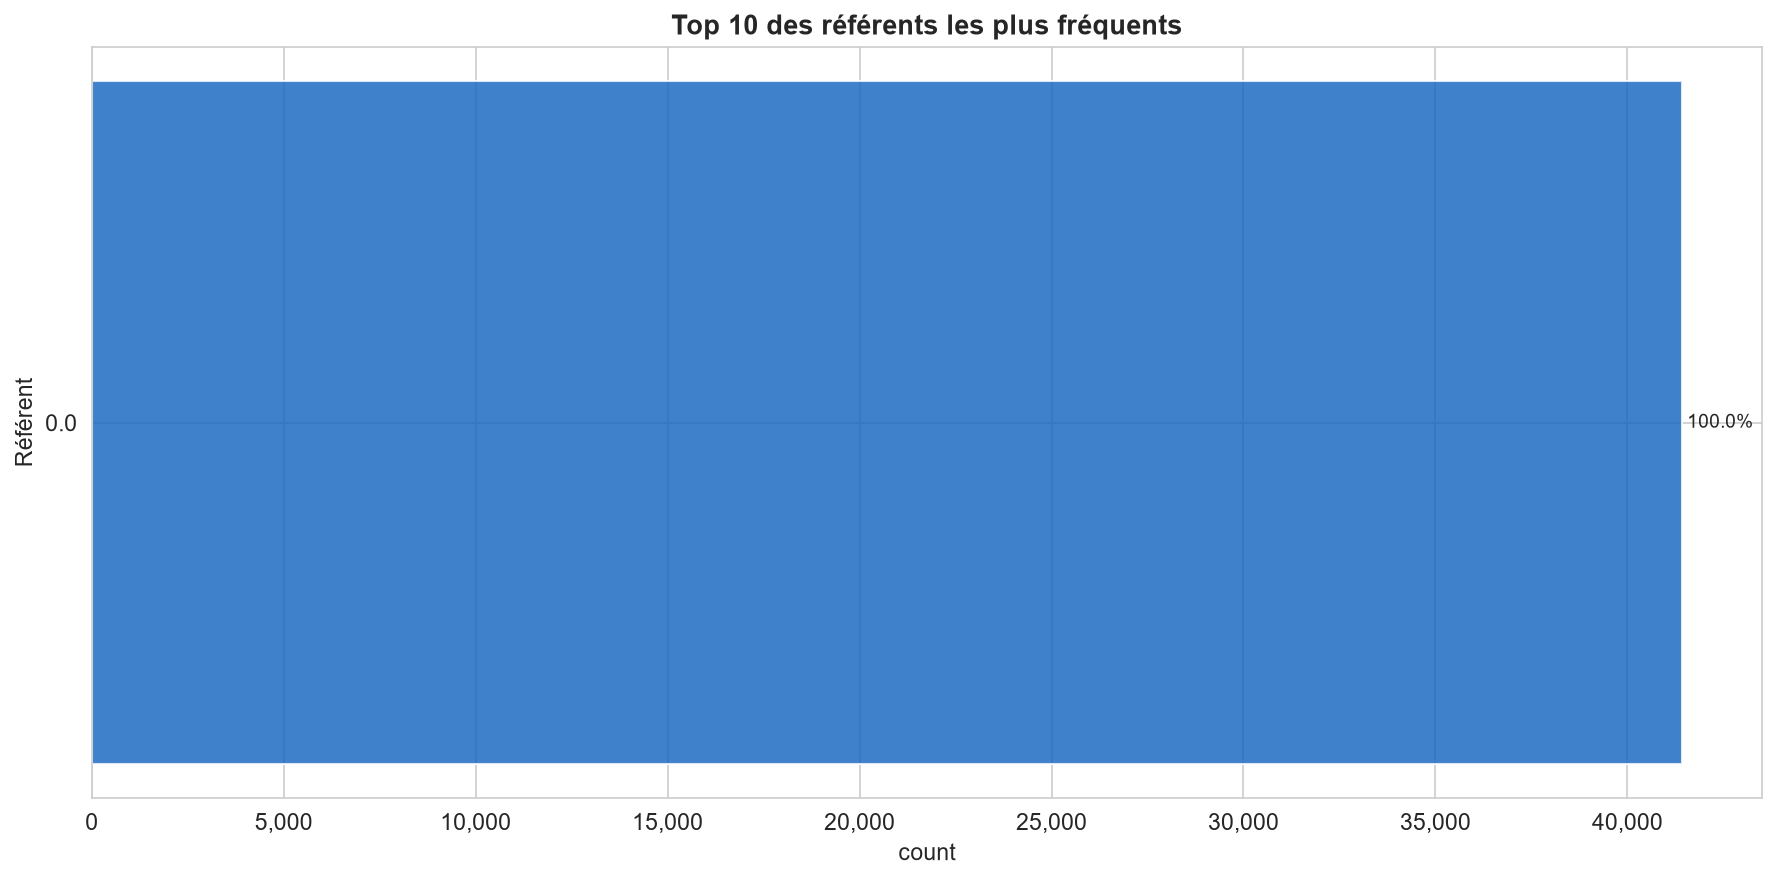

In [21]:
# ============================================================
# CELLULE 7 — FIGURE 3.7
# Distribution de la variable Référent (top 10)
# ============================================================

if 'referer' in df.columns:
    counts = (
        df[~df['referer'].isin(['unknown', '-', ''])]['referer']
        .value_counts()
        .head(10)
        .sort_values()
    )
    total = len(df)

    # Tronquer les labels trop longs
    labels = [str(l)[:55] + '…' if len(str(l)) > 55 else str(l)
              for l in counts.index]

    fig, ax = plt.subplots(figsize=(12, 6))
    bars = ax.barh(
        labels, counts.values,
        color='#1565C0', alpha=0.82, edgecolor='white'
    )

    for bar, val in zip(bars, counts.values):
        pct = val / total * 100
        ax.text(
            bar.get_width() + total * 0.003,
            bar.get_y() + bar.get_height() / 2,
            f'{pct:.1f}%', va='center', fontsize=9
        )

    ax.set_title('Top 10 des référents les plus fréquents')
    ax.set_xlabel('count')
    ax.set_ylabel('Référent')
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
    plt.tight_layout()
    save(fig, 'fig3_7_distribution_referer.png')
    plt.show()
else:
    print('⚠ Colonne "referer" absente.')

## Distribution de la variable User-Agent (Top 10)

  fig3_8_distribution_useragent.png


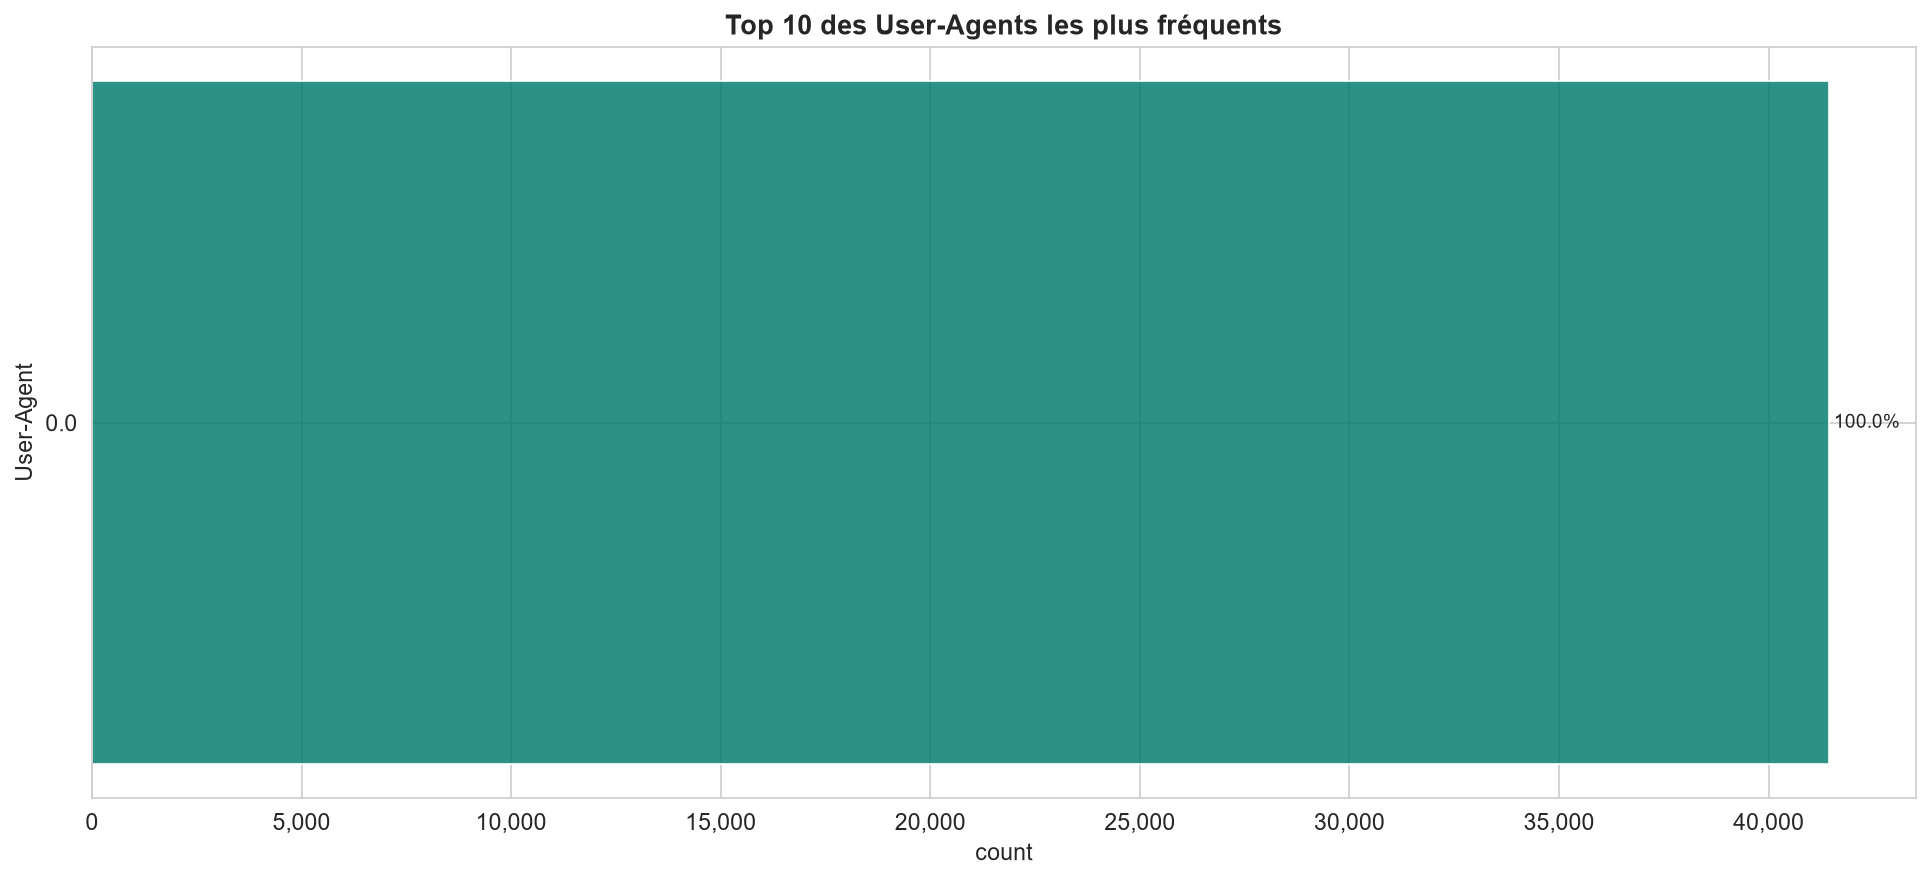

In [22]:
# ============================================================
# CELLULE 8 — FIGURE 3.8
# Distribution de la variable User-Agent (top 10)
# ============================================================

if 'user_agent' in df.columns:
    counts = (
        df[df['user_agent'] != 'unknown']['user_agent']
        .value_counts()
        .head(10)
        .sort_values()
    )
    total = len(df)
    labels = [str(l)[:60] + '…' if len(str(l)) > 60 else str(l)
              for l in counts.index]

    fig, ax = plt.subplots(figsize=(13, 6))
    bars = ax.barh(
        labels, counts.values,
        color='#00796B', alpha=0.82, edgecolor='white'
    )

    for bar, val in zip(bars, counts.values):
        pct = val / total * 100
        ax.text(
            bar.get_width() + total * 0.003,
            bar.get_y() + bar.get_height() / 2,
            f'{pct:.1f}%', va='center', fontsize=9
        )

    ax.set_title('Top 10 des User-Agents les plus fréquents')
    ax.set_xlabel('count')
    ax.set_ylabel('User-Agent')
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
    plt.tight_layout()
    save(fig, 'fig3_8_distribution_useragent.png')
    plt.show()
else:
    print('⚠ Colonne "user_agent" absente.')

## 9 -Preparation de la Matrice numérique

In [23]:
# ============================================================
# CELLULE 9 — PRÉPARATION MATRICE NUMÉRIQUE
# (utilisée pour Fig 3.9, 3.10, 3.11)
# ============================================================

# Colonnes numériques des features engineerées (§3.4 et §3.6)
FEATURE_COLS = [
    'date_hour_sin', 'date_hour_cos', 'date_normalized',
    'ip_request_count', 'ip_time_spread', 'ip_request_rate',
    'ip_subnet_activity', 'ip_error_rate', 'ip_interval_std',
    'ip_method_diversity', 'ip_max_requests_per_sec',
    'is_hierarchical', 'url_path_depth', 'url_path_struct_entropy',
    'nbre_total_url_query_params', 'url_query_special_chars_count',
    'url_path_special_chars_count', 'nbre_unique_urls_per_ip',
    'fragment_param_count', 'special_char_fragment_count',
    'user_agent_length', 'user_agent_entropy',
    'user_agent_total_special_chars', 'is_bot',
    'referer_is_present', 'referer_path_depth',
    'referer_path_struct_entropy', 'nbre_total_referer_query_params',
    'referer_query_special_chars_count',
    'method_encoded', 'status_code_category_encoded', 'country_encoded',
    'response_size',
]

# Garder uniquement les colonnes présentes
feat_available = [c for c in FEATURE_COLS if c in df.columns]

# Construire la matrice numérique
X = df[feat_available].apply(pd.to_numeric, errors='coerce').fillna(0)

# Standardiser
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=feat_available
)

print(f'✅ Matrice numérique : {X_scaled.shape[0]:,d} lignes × {X_scaled.shape[1]} features')

✅ Matrice numérique : 41,433 lignes × 31 features


## 10 - Matrice de corrélation de Pearson

  fig3_9_matrice_correlation.png


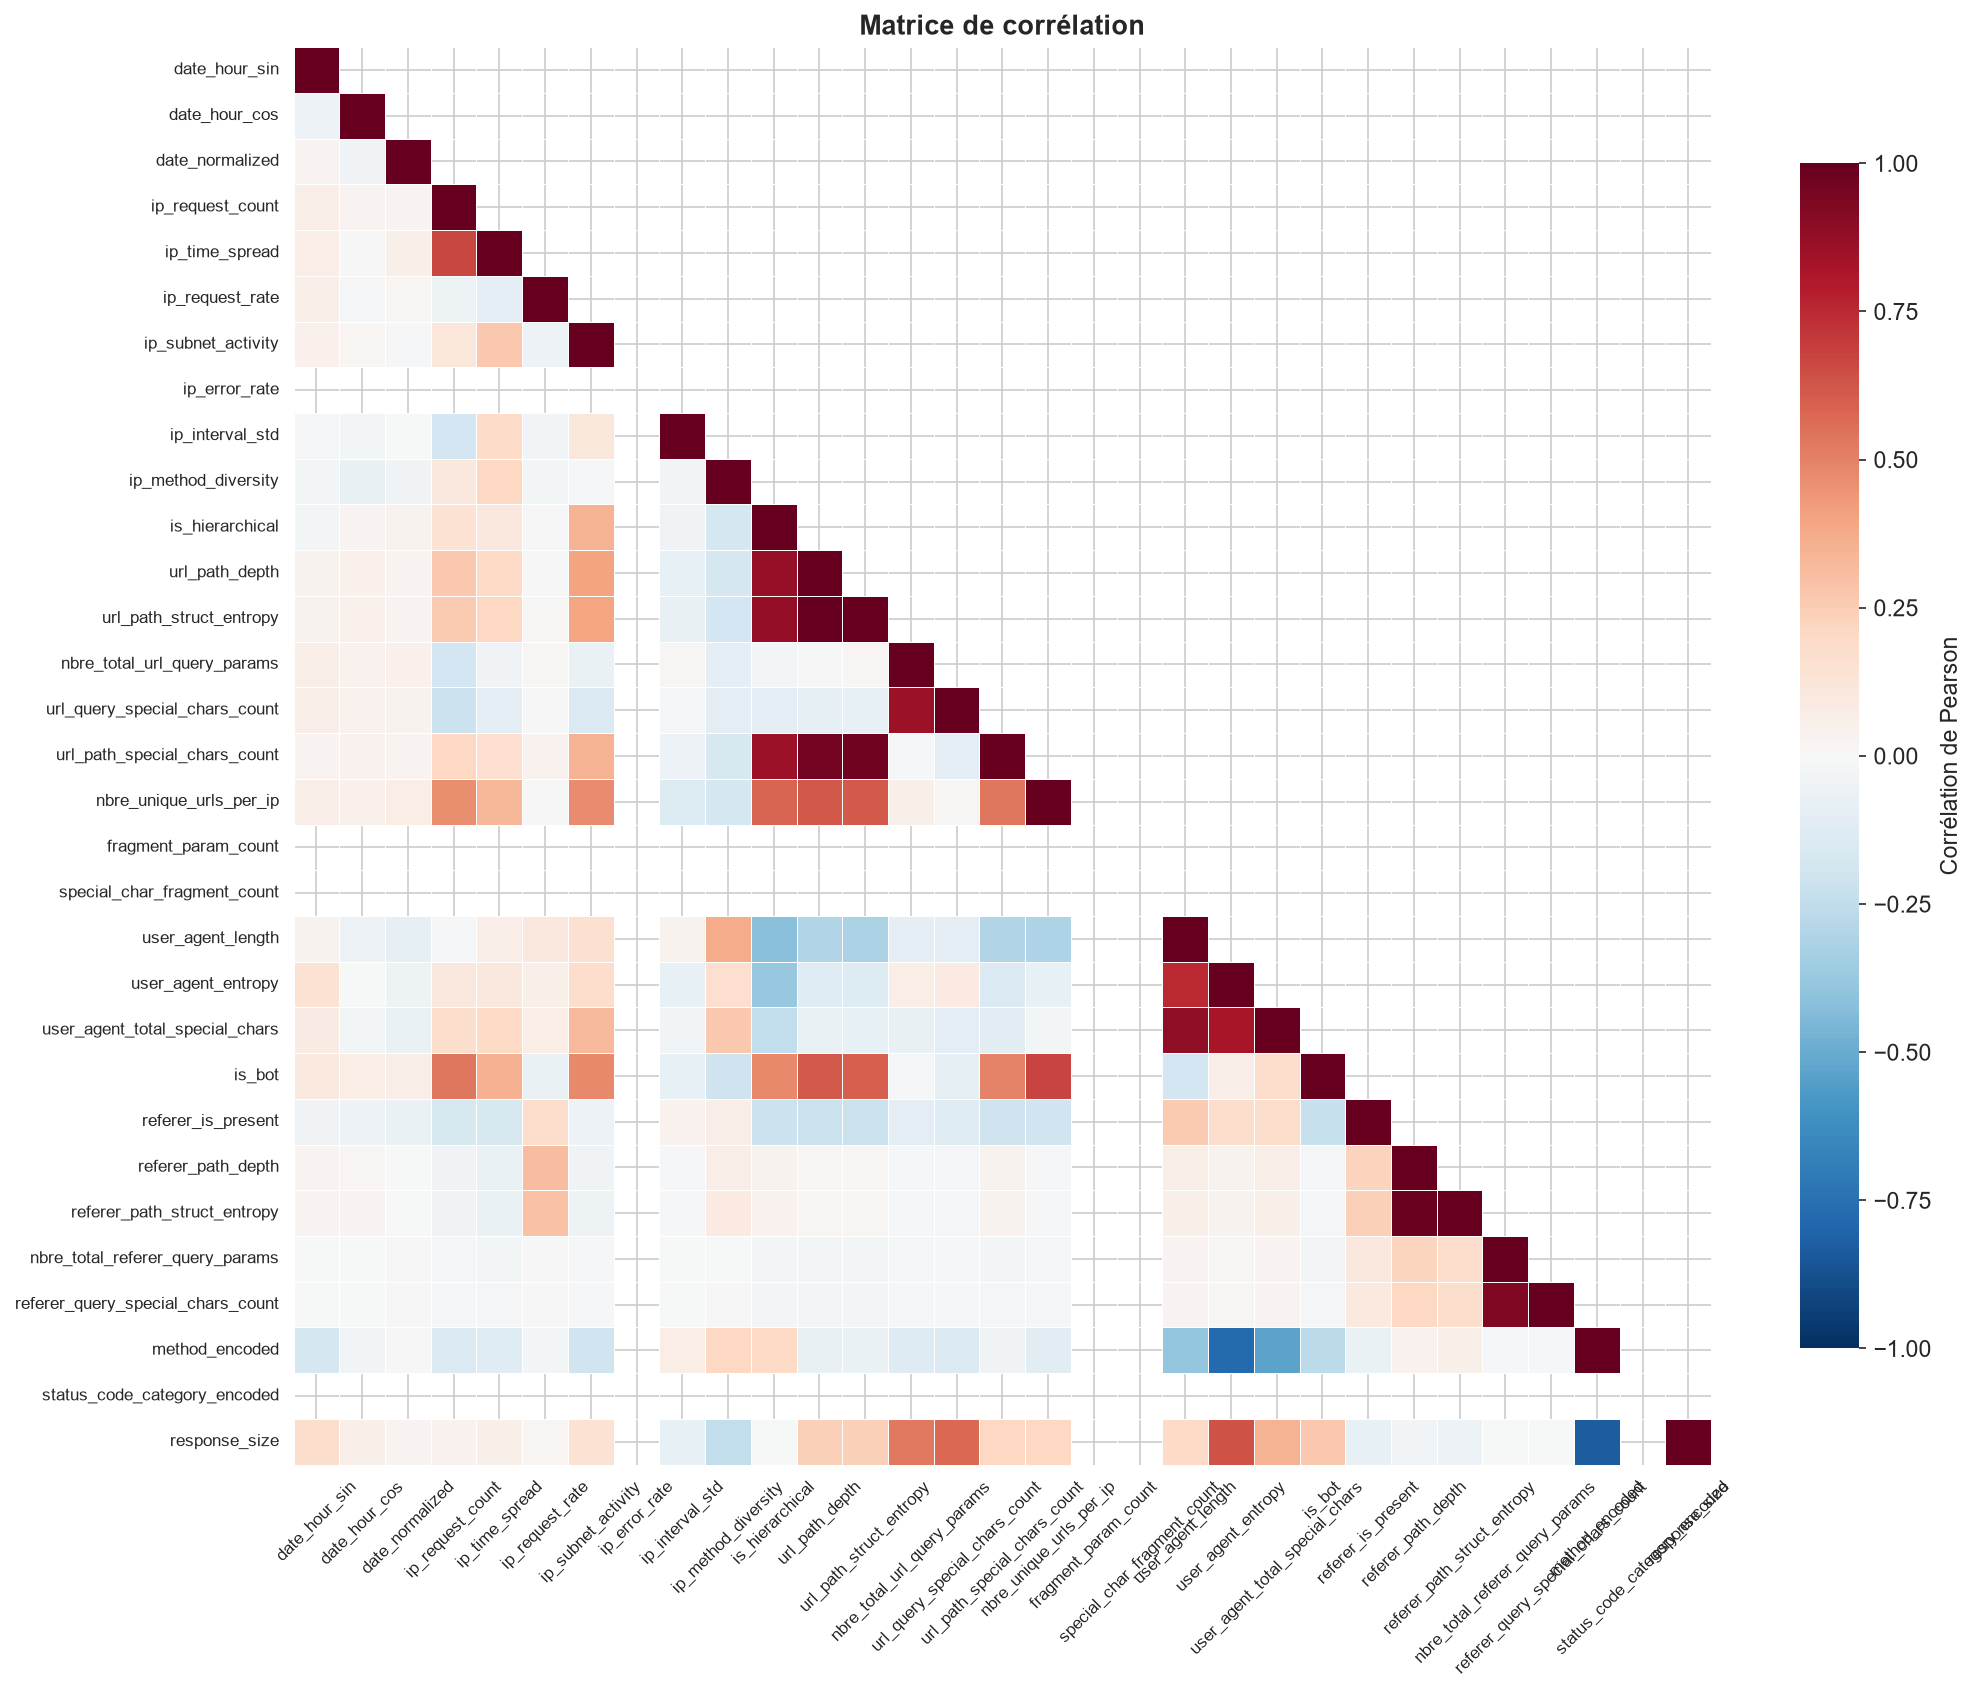

In [24]:
# ============================================================
# CELLULE 10 — FIGURE 3.9
# Matrice de corrélation de Pearson (§3.10.1)
# ============================================================

corr = X_scaled.corr(method='pearson')

fig, ax = plt.subplots(figsize=(14, 12))
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask, k=1)] = True   # masquer triangle supérieur

sns.heatmap(
    corr,
    ax          = ax,
    mask        = mask,
    cmap        = 'RdBu_r',
    vmin        = -1, vmax = 1,
    annot       = len(feat_available) <= 20,   # annotations si peu de variables
    fmt         = '.2f',
    square      = True,
    linewidths  = 0.3,
    cbar_kws    = {'shrink': 0.75, 'label': 'Corrélation de Pearson'},
)
ax.set_title('Matrice de corrélation')
ax.tick_params(axis='x', rotation=45, labelsize=8)
ax.tick_params(axis='y', rotation=0,  labelsize=8)
plt.tight_layout()
save(fig, 'fig3_9_matrice_correlation.png')
plt.show()

## 11 -Matrice de corrélation et Clustering hierarchique

In [25]:
# ============================================================
# CELLULE 11 — FIGURE 3.10
# Matrice de corrélation + Clustering hiérarchique 
# ============================================================

# Clustering hiérarchique sur les variables (méthode de Ward)
linkage_matrix = linkage(corr.values, method='ward')
order = dendrogram(linkage_matrix, no_plot=True)['leaves']
corr_reordered = corr.iloc[order, :].iloc[:, order]

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    corr_reordered,
    ax         = ax,
    cmap       = 'RdBu_r',
    vmin       = -1, vmax = 1,
    square     = True,
    linewidths = 0.3,
    cbar_kws   = {'shrink': 0.75},
    xticklabels = corr_reordered.columns,
    yticklabels = corr_reordered.index,
)
ax.set_title('Matrice de corrélation et Clustering hiérarchique')
ax.tick_params(axis='x', rotation=45, labelsize=7)
ax.tick_params(axis='y', rotation=0,  labelsize=7)

# Ajouter la légende des clusters
n_clusters = min(22, len(feat_available))
cluster_labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
unique_clusters = len(np.unique(cluster_labels))
ax.set_xlabel(f'Variables ({unique_clusters} clusters identifiés — méthode Ward)')

plt.tight_layout()
save(fig, 'fig3_10_correlation_clustering.png')
plt.show()

# Afficher les clusters identifiés (comme §3.13.1)
print('\n  Clusters identifiés :')
var_names = [feat_available[i] for i in order]
labels_ordered = cluster_labels[order]
for cl in sorted(np.unique(labels_ordered)):
    members = [v for v, l in zip(var_names, labels_ordered) if l == cl]
    print(f'  Cluster {cl:>2} : {members}')

ValueError: The condensed distance matrix must contain only finite values.

## 12 Variance cumulée expliquée par les composantes principales

In [ ]:
# ============================================================
# CELLULE 12 — FIGURE 3.11
# Variance cumulée expliquée par les composantes principales ()
# Objectif : trouver le nombre de composantes pour 99% de variance
# ============================================================

pca_full = PCA(n_components=X_scaled.shape[1])
pca_full.fit(X_scaled)

cumvar   = np.cumsum(pca_full.explained_variance_ratio_)
n_comp   = int(np.argmax(cumvar >= 0.99)) + 1
x_range  = np.arange(1, len(cumvar) + 1)

fig, ax = plt.subplots(figsize=(10, 5))

# Courbe variance cumulée
ax.plot(
    x_range, cumvar,
    color='royalblue', lw=2, marker='o', markersize=5,
    label='Variance cumulée'
)

# Ligne 99 %
ax.axhline(
    y=0.99, color='red', linestyle='--', lw=1.5,
    label='99% de variance'
)

# Ligne seuil composantes
ax.axvline(
    x=n_comp, color='green', linestyle='--', lw=1.5,
    label=f'{n_comp} composantes'
)

# Annotation
ax.annotate(
    f'{n_comp} composantes\n→ {cumvar[n_comp-1]*100:.1f}% variance',
    xy=(n_comp, cumvar[n_comp - 1]),
    xytext=(n_comp + 1, 0.80),
    arrowprops=dict(arrowstyle='->', color='black'),
    fontsize=10, color='darkgreen'
)

ax.set_title('Variance cumulée expliquée par les composantes principales')
ax.set_xlabel('Nombre de composantes principales')
ax.set_ylabel('Variance cumulée expliquée')
ax.set_ylim(0, 1.05)
ax.set_xlim(0, len(cumvar) + 1)
ax.legend(loc='lower right')
ax.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1))
ax.grid(True, alpha=0.4)
plt.tight_layout()
save(fig, 'fig3_11_pca_variance_cumulee.png')
plt.show()

print(f'\n  → {n_comp} composantes suffisent pour expliquer 99% de la variance')
print(f'  → Réduction : {X_scaled.shape[1]} variables → {n_comp} composantes')

## 13 Rapport final

In [ ]:
# ============================================================
# CELLULE 13 — RAPPORT FINAL
# ============================================================

figures = sorted(FIGURES_DIR.glob('*.png'))

print('=' * 65)
print('📊 RAPPORT FINAL — Visualisations générées')
print('=' * 65)
print(f'  Dossier : {FIGURES_DIR}')
print(f'  Fichiers générés : {len(figures)}')
print()

mapping = {
    'fig3_3_heatmap_annee_mois.png'     : 'Figure 3.3  — Heatmap répartition logs par année et mois',
    'fig3_4_repartition_temporelle.png' : 'Figure 3.4  — Répartition temporelle des logs',
    'fig3_5_distribution_methodes.png'  : 'Figure 3.5  — Distribution de la variable Méthodes',
    'fig3_6_distribution_statuscode.png': 'Figure 3.6  — Distribution de la variable Status_code',
    'fig3_7_distribution_referer.png'   : 'Figure 3.7  — Distribution de la variable Référent',
    'fig3_8_distribution_useragent.png' : 'Figure 3.8  — Distribution de la variable User_Agent',
    'fig3_9_matrice_correlation.png'    : 'Figure 3.9  — Matrice de corrélation',
    'fig3_10_correlation_clustering.png': 'Figure 3.10 — Matrice de corrélation + Clustering hiérarchique',
    'fig3_11_pca_variance_cumulee.png'  : 'Figure 3.11 — Nombre de composantes pour 99% de la variance',
}

for fig_path in figures:
    size_kb = fig_path.stat().st_size / 1024
    label   = mapping.get(fig_path.name, fig_path.name)
    print(f'  ✅ {label}')
    print(f'     {fig_path.name}  ({size_kb:.0f} KB)')
    print()

print('=' * 65)